In [ ]:
import pickle as pck
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
# import pylandau as pland
# import ROOT
import sys

from ROOT import TFile, TTree
from array import array

Welcome to JupyROOT 6.28/04


In [2]:
###   Abrir el archivo que se va a escribir en el arbol de ROOT 
path = './Diccionarios_Espetro_Muones/dict_energy_allclusters_NSAMP324_Extensions_1_to_4_Imgs_393_SIZE_300x529__NSIGMAS_5_KeV.pkl'
# path = './Diccionarios_Espetro_Muones/dict_energy_allclusters_NSAMP324_Extensions_1_to_4_Imgs_393_SIZE_250x529__NSIGMAS_5_KeV.pkl'


histogram = open(path, 'rb')
data_histogram = pck.load(histogram)
histogram.close()

In [ ]:
### Separar los datos del archivo para poder iterar en ellos ###
data_muons_extension_1 = data_histogram['extension_1']
data_muons_extension_2 = data_histogram['extension_2']
data_muons_extension_4 = data_histogram['extension_4']

data_muons_extension_1.keys()

dict_keys(['charge'])

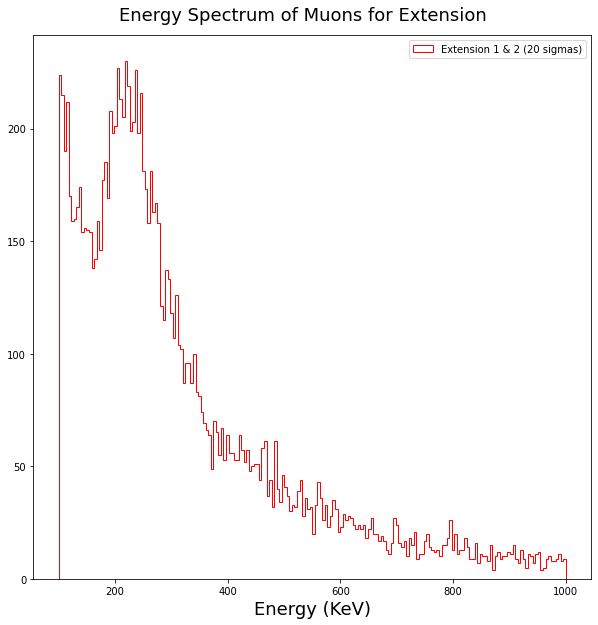

In [5]:
data_ext_1_2 = data_muons_extension_1['charge'] + data_muons_extension_2['charge']

Bins = 200
max_energy = 1000
min_energy = 100
fig, axs = plt.subplots(figsize = [10,10])
axs.hist(data_ext_1_2, bins = Bins, range = [min_energy, max_energy], color = 'r', label= 'Extension 1 & 2 (20 sigmas)',  histtype = 'step')

axs.legend()
# axs.set_yscale('log')
# axs.set_ylim(50, 700)
axs.set_xlabel('Energy (KeV)', size = 18,loc='center')
# axs.set_ylabel('Counts', size = 18)
fig.suptitle('Energy Spectrum of Muons for Extension', size = 18, y=0.92)
plt.show()

In [ ]:
### Generar un array para cada variable que se quiere meter ###
Energy_Landau_array = array('f', [-9999])

### Abrir el archivo donde se va a guardar el arbol ###
location_file = '../Simulacion_ab_initio/'
file_root_name = 'Ejemplo_arbolROOT.root'
file = TFile.Open(location_file  + file_root_name, "RECREATE")

### Generar un objeto TTree ###
tree = TTree('tree', 'tree')

### Generar una rama para cada variable que se va a guardar ###
tree.Branch('edep', Energy_Landau_array, 'edep/F')

### Iterar en la lista, guardar en el arreglo asociado y escribir el arbol ###
for i in np.arange(0, len(data_ext_1_2)):
    Energy_Landau_array[0] = data_ext_1_2[i]
    
    tree.Fill()

tree.Write()
file.Close()